In [1]:
import pyC2C as c2c
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Load source data and results data frame

In [ ]:
# load fid or ms data
raw_data = c2c.load_file('sample_data/shimdazu_C2C005.qgd')
raw_data.getBPC()

0
10000
20000
30000
40000
50000
60000
70000
80000
90000
100000
Number of MS1 scans: 106680


In [3]:
results_df = pd.read_csv('C2C-005_results.csv', sep=',')
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z),LRI
0,6.1158,6.10,1.95,21049.0,1,66.05:7.42 67.0:6.38 67.1:25.33 67.15:9.37 67....,103.10,-1,610
1,6.0708,6.03,3.25,6014.0,2,65.0:25.09 66.0:20.43 66.1:8.64 67.1:50.38 68....,203.00,15,603
2,9.5858,9.57,2.15,26802.0,3,63.0:5.04 65.0:14.04 66.0:5.91 66.1:6.08 66.15...,127.20,9,812
3,9.7208,9.70,2.25,13021.0,4,65.0:14.3 66.1:5.15 66.15:13.88 66.2:5.51 66.2...,127.15,9,816
4,10.0542,10.03,2.25,82421.0,5,65.0:6.14 66.0:7.06 67.05:5.31 67.1:8.11 67.2:...,127.20,9,825


### Get DBE

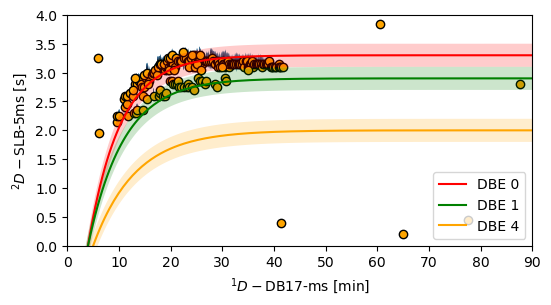

In [4]:
dbe0 = c2c.DBELine(0, 3.3, 30, 4, 0.05)
dbe1 = c2c.DBELine(1, 2.9, 32, 4, 0.05)
# dbe2 = c2c.DBELine(2, 2.75, 26, 5, 0.05)
dbe4 = c2c.DBELine(4, 2.0, 35, 5, 0.05)

xmin = 0
xmax = 90
ymin = 0
ymax = 4

show_tolerance = True

fig, ax = plt.subplots(figsize=(6, 3))

c2c.plot2d(fig, ax, raw_data.rt, raw_data.bpc,
           mod_time=4,
           shift=1, 
           color_range=(8, 80),
           cbar=False,
           axis_labels=('DB17-ms', 'SLB-5ms'),
           solvent_cut=0)

ax.scatter(results_df['RT 1d (min)'], results_df['RT 2d (s)'],
           color='orange', edgecolors='black')

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# plot lines
x = np.linspace(xmin, xmax, num=200)

dbe0.plotLine(ax, x, 0.2, 'DBE 0', 'red', show_tolerance=show_tolerance)
dbe1.plotLine(ax, x, 0.2, 'DBE 1', 'green', show_tolerance=show_tolerance)
# dbe2.plotLine(ax, x, 0.2,  'DBE 2', 'blue', show_tolerance=show_tolerance)
dbe4.plotLine(ax, x, 0.2, 'DBE 4', 'orange', show_tolerance = show_tolerance)

ax.legend()
# ax.grid(color='black')

plt.show()

In [5]:
results_df['DBE'] = c2c.getDBE(results_df, [dbe0, dbe1, dbe4])
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z),LRI,DBE
0,6.1158,6.10,1.95,21049.0,1,66.05:7.42 67.0:6.38 67.1:25.33 67.15:9.37 67....,103.10,-1,610,-1
1,6.0708,6.03,3.25,6014.0,2,65.0:25.09 66.0:20.43 66.1:8.64 67.1:50.38 68....,203.00,15,603,-1
2,9.5858,9.57,2.15,26802.0,3,63.0:5.04 65.0:14.04 66.0:5.91 66.1:6.08 66.15...,127.20,9,812,0
3,9.7208,9.70,2.25,13021.0,4,65.0:14.3 66.1:5.15 66.15:13.88 66.2:5.51 66.2...,127.15,9,816,-1
4,10.0542,10.03,2.25,82421.0,5,65.0:6.14 66.0:7.06 67.05:5.31 67.1:8.11 67.2:...,127.20,9,825,0


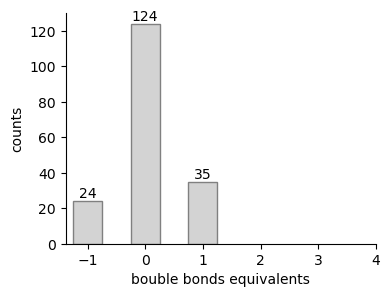

In [6]:
# bar plot

dbe_counts = np.unique(results_df['DBE'], return_counts=True)
    
fig, ax = plt.subplots(figsize=(4, 3))

plot = ax.bar(dbe_counts[0], dbe_counts[1], width=0.5, color='lightgray', edgecolor='gray')
ax.bar_label(plot)
ax.set_ylabel('counts')
ax.set_xlabel('bouble bonds equivalents')
ax.set_xticks(range(-1, 5))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()

### Start CNum object and create retention time ranges

In [13]:
cnum_class = c2c.CNum()
cnum_class.create_cnumItem('0', cnum_list=[7, 8, 9, 10, 11, 12, 13, 14, 15],
                           mz_list= [99, 113, 127, 141, 155, 169, 183, 197, 211],
                           c_ranges = [[(6.5, 1.7), (7.7, 2.0)],
                                       [(7.9, 2.1), (10.1, 2.4)],
                                       [(9.5, 2.5), (13.7, 2.8)], 
                                       [(12.0, 3.0), (17.3, 3.0)],
                                       [(14.4, 3.2), (20.5, 3.2)],
                                       [(17.7, 3.3), (26.7, 3.0)],
                                       [(23.7, 3.3), (31.2, 3.0)],
                                       [(28.8, 3.3), (35.9, 3.0)],
                                       [(32.8, 3.3), (39.2, 3.0)]]
)

display(cnum_class.cnum_ranges)

{'0': {7: {'rt1': [6.5, 7.7],
   'rt2': [1.7, 2.0],
   'slope': 0.25,
   'intercept': 0.075,
   'm/z': 99},
  8: {'rt1': [7.9, 10.1],
   'rt2': [2.1, 2.4],
   'slope': 0.136,
   'intercept': 1.023,
   'm/z': 113},
  9: {'rt1': [9.5, 13.7],
   'rt2': [2.5, 2.8],
   'slope': 0.071,
   'intercept': 1.821,
   'm/z': 127},
  10: {'rt1': [12.0, 17.3],
   'rt2': [3.0, 3.0],
   'slope': 0.0,
   'intercept': 3.0,
   'm/z': 141},
  11: {'rt1': [14.4, 20.5],
   'rt2': [3.2, 3.2],
   'slope': 0.0,
   'intercept': 3.2,
   'm/z': 155},
  12: {'rt1': [17.7, 26.7],
   'rt2': [3.3, 3.0],
   'slope': -0.033,
   'intercept': 3.89,
   'm/z': 169},
  13: {'rt1': [23.7, 31.2],
   'rt2': [3.3, 3.0],
   'slope': -0.04,
   'intercept': 4.248,
   'm/z': 183},
  14: {'rt1': [28.8, 35.9],
   'rt2': [3.3, 3.0],
   'slope': -0.042,
   'intercept': 4.517,
   'm/z': 197},
  15: {'rt1': [32.8, 39.2],
   'rt2': [3.3, 3.0],
   'slope': -0.047,
   'intercept': 4.837,
   'm/z': 211}}}

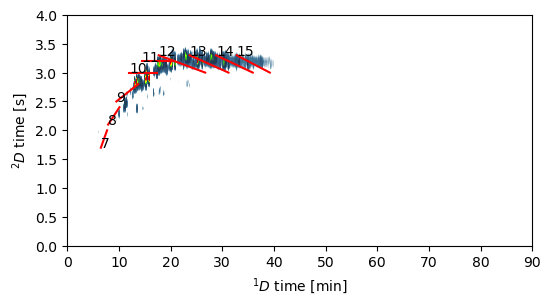

In [14]:
# draw lines

fig, ax = plt.subplots(figsize=(6, 3))

c2c.plot2d(fig, ax, raw_data.rt, raw_data.bpc, 4, shift=1, cbar=False, color_range=(8, 80))

ax.set_xlim(0, 90)
ax.set_ylim()

for k in cnum_class.cnum_ranges['0'].keys():
     ax.plot(cnum_class.cnum_ranges['0'][k]['rt1'],
            cnum_class.cnum_ranges['0'][k]['rt2'], color='red')
     ax.text(cnum_class.cnum_ranges['0'][k]['rt1'][0],
             cnum_class.cnum_ranges['0'][k]['rt2'][0],
             s=str(k))

plt.show()


In [15]:
results_df['CNum (RT)'] = cnum_class.get_cnum(results_df)
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z),LRI,DBE,CNum (RT)
0,6.1158,6.10,1.95,21049.0,1,66.05:7.42 67.0:6.38 67.1:25.33 67.15:9.37 67....,103.10,-1,610,-1,-1
1,6.0708,6.03,3.25,6014.0,2,65.0:25.09 66.0:20.43 66.1:8.64 67.1:50.38 68....,203.00,15,603,-1,-1
2,9.5858,9.57,2.15,26802.0,3,63.0:5.04 65.0:14.04 66.0:5.91 66.1:6.08 66.15...,127.20,9,812,0,8
3,9.7208,9.70,2.25,13021.0,4,65.0:14.3 66.1:5.15 66.15:13.88 66.2:5.51 66.2...,127.15,9,816,-1,-1
4,10.0542,10.03,2.25,82421.0,5,65.0:6.14 66.0:7.06 67.05:5.31 67.1:8.11 67.2:...,127.20,9,825,0,8


In [ ]:
# export data frame
results_df.to_csv('sample_data/C2C-005_results.csv', sep=',', index=False)